# **실습 개요**

여러분은 와인 감정 스타트업의 데이터 분석팀에 합류했습니다. <br>
이 회사는 와인의 화학 성분 분석 결과만으로 와인의 포도 품종(Cabernet Sauvignon / Merlot / Pinot Noir)을 <br>
자동으로 판별하는 모델을 만들어, 와이너리의 품질 관리 및 블라인드 테이스팅 검증에 활용하려고 합니다.

이번 실습에서는 **PyTorch `nn.Module` 기반 MLP**로 다중 분류 모델을 만듭니다.

## **데이터셋 설명**

와인 1,120병에 대한 화학 성분 분석 결과와 실제 포도 품종(정답)을 담은 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| alcohol | 알코올 함량 (%) |
| malic_acid | 사과산 함량 (g/L) |
| ash | 회분 함량 (g/L) |
| alcalinity_of_ash | 회분의 알칼리도 |
| magnesium | 마그네슘 함량 (mg/L) |
| total_phenols | 총 페놀 함량 |
| flavanoids | 플라보노이드 함량 |
| nonflavanoid_phenols | 비플라보노이드 페놀 함량 |
| proanthocyanins | 프로안토시아닌 함량 |
| color_intensity | 색상 강도 |
| hue | 색조 |
| od280_od315 | 단백질 함량 추정 흡광도 비율 (OD280/OD315) |
| proline | 프롤린(아미노산) 함량 |
| oak_aged | 오크통 숙성 여부 (Yes/No) |
| variety | **[target]** 포도 품종 (Cabernet Sauvignon / Merlot / Pinot Noir) |

## **이진 분류 vs 다중 분류**

| | 이진 분류 | 다중 분류 |
|---|---|---|
| 클래스 수 | 2개 | 3개 이상 |
| 출력층 | `Linear → Sigmoid` | `Linear` (Softmax 없음) |
| 손실 함수 | `BCELoss` | `CrossEntropyLoss` |
| 레이블 dtype | `float32` | `long` |

- CrossEntropyLoss는 내부적으로 Softmax를 포함하므로, 출력층에 Softmax를 따로 달면 이중 적용됩니다.

## **데이터셋 URL**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety.csv

## **1. 데이터 살펴보기**

**Q1. 필요한 라이브러리를 불러오고, 데이터를 읽어온 뒤 첫 5개의 행을 출력하세요.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety.csv")
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,oak_aged,variety
0,11.785199,1.169833,2.306773,24.208038,89.593547,2.290849,2.108096,0.243616,1.100715,3.786747,1.169956,2.721544,624.712679,No,Merlot
1,11.122725,4.103022,2.469871,19.018421,84.185270,2.201615,1.719580,0.295145,1.493834,3.831402,0.750554,1.774096,550.372477,NaN,Merlot
2,12.315376,1.079129,1.386586,25.770385,90.590014,1.280029,1.166926,0.420398,0.948833,3.828069,1.199902,2.289818,698.951732,Yes,Merlot
3,12.724482,0.879105,2.524974,17.036320,101.330910,3.054305,2.804751,0.322099,1.730976,5.741020,1.369589,3.248187,1331.241565,Yes,Cabernet Sauvignon
4,12.141689,1.730578,1.572926,17.286193,74.038796,2.123239,1.928006,0.310430,0.769692,2.921799,1.291609,2.859367,705.963614,Yes,Merlot


**Q2. 데이터의 크기와 컬럼별 정보를 확인합니다.**

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1120 entries, 0 to 1119
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   alcohol               1120 non-null   float64
 1   malic_acid            1076 non-null   float64
 2   ash                   1120 non-null   float64
 3   alcalinity_of_ash     1120 non-null   float64
 4   magnesium             1042 non-null   float64
 5   total_phenols         1120 non-null   float64
 6   flavanoids            1120 non-null   float64
 7   nonflavanoid_phenols  1120 non-null   float64
 8   proanthocyanins       1009 non-null   float64
 9   color_intensity       1120 non-null   float64
 10  hue                   950 non-null    float64
 11  od280_od315           1120 non-null   float64
 12  proline               1120 non-null   float64
 13  oak_aged              1065 non-null   str    
 14  variety               1120 non-null   str    
dtypes: float64(13), str(2)
memory us

**Q3. 수치형 컬럼들의 기술 통계량을 확인합니다.**

In [3]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
count,1120.000000,1076.000000,1120.000000,1120.000000,1042.000000,1120.000000,1120.000000,1120.000000,1009.000000,1120.000000,950.000000,1120.000000,1120.000000
mean,13.066331,2.392728,2.380684,19.429161,99.464946,2.261206,2.084462,0.359310,1.581669,5.260124,0.950130,2.239949,748.218360
std,0.743732,1.132270,0.268746,3.375890,13.667743,0.617484,0.591677,0.121769,0.564194,2.371496,0.232600,0.519387,325.478965
min,10.105443,0.010000,1.384772,9.610953,42.431242,0.631154,0.545046,0.010000,0.010000,0.010000,0.252342,1.000000,0.100000
25%,12.536712,1.661629,2.220090,17.169921,90.771697,1.750480,1.612300,0.274527,1.184345,3.397556,0.750700,1.802643,514.353543
50%,13.113841,2.294375,2.401088,19.488909,99.778662,2.280092,2.086256,0.347769,1.597912,5.010499,0.974036,2.328159,665.046603
75%,13.598016,2.986024,2.552149,21.743173,108.523987,2.779385,2.551304,0.431901,1.956663,6.638302,1.125602,2.643533,971.807935
max,15.156931,6.818836,3.232603,29.440284,150.495520,3.943020,3.736051,0.813198,4.015494,13.996794,1.747186,3.769422,2080.316615


## **2. 데이터 분석하기**

### **2-1. 데이터 탐색하기**

**Q1. 품종(variety)별 데이터의 개수를 찾아 주세요.**

In [4]:
q1 = df["variety"].value_counts()
q1

variety
Merlot                386
Cabernet Sauvignon    386
Pinot Noir            348
Name: count, dtype: int64

**Q2. 품종별로 alcohol, flavanoids, color_intensity의 평균을 소수점 2자리까지 구해 비교해 주세요.**

In [5]:
q2 = df.groupby("variety")[["alcohol", "flavanoids", "color_intensity"]].mean().round(2)
q2

,alcohol,flavanoids,color_intensity
variety,,,
Cabernet Sauvignon,13.70,2.60,5.45
Merlot,12.31,2.04,3.14
Pinot Noir,13.20,1.55,7.40


### **2-1. 데이터 시각화**

**Q1. alcohol 컬럼의 분포를 품종별로 histogram으로 시각화하세요.**

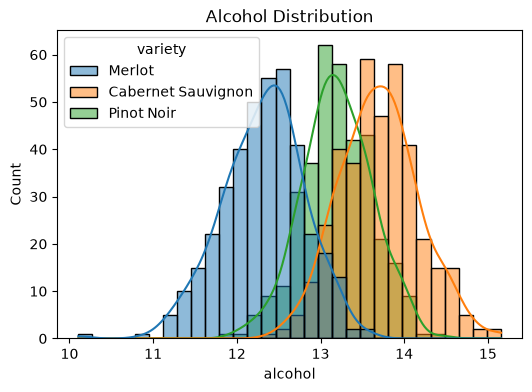

In [6]:
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="alcohol", bins=30, kde=True, hue="variety")
plt.title("Alcohol Distribution")
plt.show()

**Q2. 품종별 proline의 평균을 barplot으로 시각화하세요.**

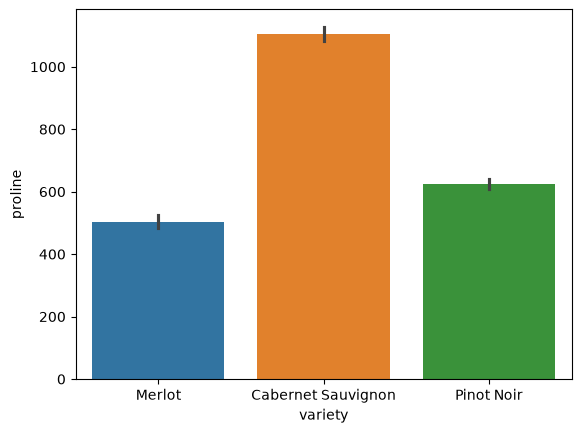

In [7]:
sns.barplot(data=df, x="variety", y="proline", hue="variety")
plt.show()

**Q3. 수치형 컬럼들의 상관관계 Heatmap을 시각화하세요.**

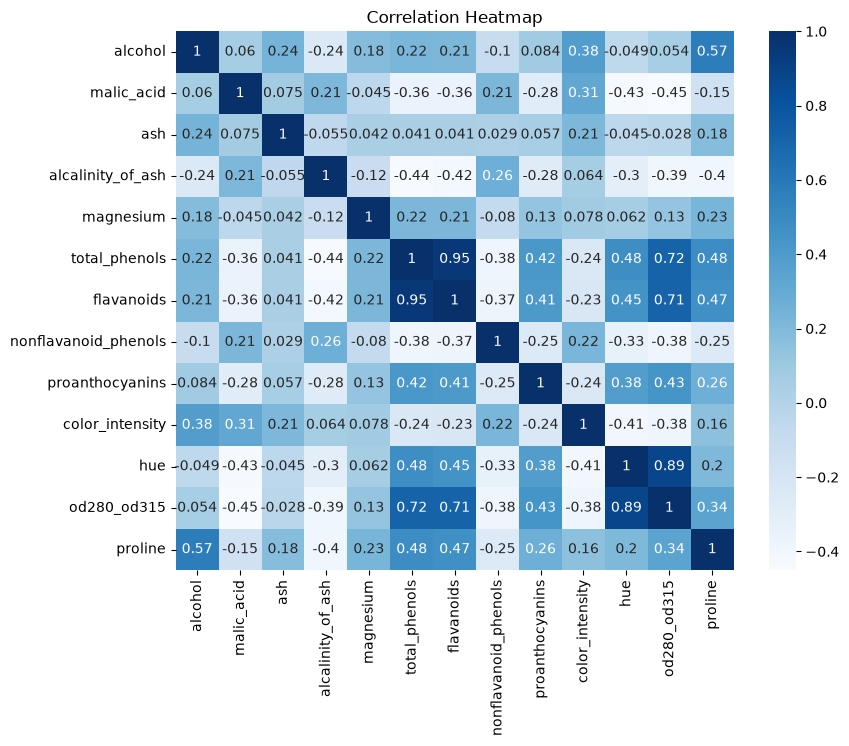

In [8]:
num_cols = df.select_dtypes(include="number").columns
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="Blues")
plt.title("Correlation Heatmap")
plt.show()

## **3. 데이터 전처리하기**

In [9]:
# 전처리 과정에서 데이터가 망가지면 여기서부터!
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety.csv")
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,oak_aged,variety
0,11.785199,1.169833,2.306773,24.208038,89.593547,2.290849,2.108096,0.243616,1.100715,3.786747,1.169956,2.721544,624.712679,No,Merlot
1,11.122725,4.103022,2.469871,19.018421,84.185270,2.201615,1.719580,0.295145,1.493834,3.831402,0.750554,1.774096,550.372477,NaN,Merlot
2,12.315376,1.079129,1.386586,25.770385,90.590014,1.280029,1.166926,0.420398,0.948833,3.828069,1.199902,2.289818,698.951732,Yes,Merlot
3,12.724482,0.879105,2.524974,17.036320,101.330910,3.054305,2.804751,0.322099,1.730976,5.741020,1.369589,3.248187,1331.241565,Yes,Cabernet Sauvignon
4,12.141689,1.730578,1.572926,17.286193,74.038796,2.123239,1.928006,0.310430,0.769692,2.921799,1.291609,2.859367,705.963614,Yes,Merlot


### **3-1. 중복 데이터 제거하기**

In [10]:
print("중복 행:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("제거 후 shape:", df.shape)

중복 행: 20
제거 후 shape: (1100, 15)


### **3-2. 데이터 분리하기**

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["variety"])
y = df["variety"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=101
)
print("학습:", X_train.shape, "  테스트:", X_test.shape)

학습: (770, 14)   테스트: (330, 14)


### **3-3. 결측치 처리하기**

In [12]:
print(X_train.isnull().sum())

alcohol                   0
malic_acid               29
ash                       0
alcalinity_of_ash         0
magnesium                55
total_phenols             0
flavanoids                0
nonflavanoid_phenols      0
proanthocyanins          81
color_intensity           0
hue                     110
od280_od315               0
proline                   0
oak_aged                 37
dtype: int64


In [13]:
# 수치형 컬럼 → 중앙값
cols_to_impute = ["malic_acid", "magnesium", "proanthocyanins", "hue"]
for col in cols_to_impute:
    median_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_val)
    X_test[col]  = X_test[col].fillna(median_val)

# 범주형 컬럼 oak_aged → 최빈값
mode_val = X_train["oak_aged"].mode()[0]
X_train["oak_aged"] = X_train["oak_aged"].fillna(mode_val)
X_test["oak_aged"]  = X_test["oak_aged"].fillna(mode_val)

print(X_train.isnull().sum())

alcohol                 0
malic_acid              0
ash                     0
alcalinity_of_ash       0
magnesium               0
total_phenols           0
flavanoids              0
nonflavanoid_phenols    0
proanthocyanins         0
color_intensity         0
hue                     0
od280_od315             0
proline                 0
oak_aged                0
dtype: int64


### **3-4. 이상치 처리하기**

In [14]:
def find_whiskers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    iqr = Q3 - Q1
    return Q1 - 1.5*iqr, Q3 + 1.5*iqr

numeric_cols = X_train.select_dtypes(include=[np.number]).columns
d = {}
for c in numeric_cols:
    lower, upper = find_whiskers(X_train, c)
    d[c] = (lower, upper)

for c in numeric_cols:
    X_train[c] = X_train[c].clip(d[c][0], d[c][1])
    X_test[c]  = X_test[c].clip(d[c][0], d[c][1])

### **3-5. Feature Encoding**

**Q1. oak_aged 컬럼을 인코딩하세요.**

In [15]:
from sklearn.preprocessing import LabelEncoder

le_oak = LabelEncoder()
X_train["oak_aged"] = le_oak.fit_transform(X_train["oak_aged"])
X_test["oak_aged"]  = le_oak.transform(X_test["oak_aged"])

**Q2. variety 레이블을 정수(0, 1, 2)로 인코딩하세요.**

In [16]:
le_var = LabelEncoder()
y_train_enc = le_var.fit_transform(y_train)
y_test_enc  = le_var.transform(y_test)

print("클래스 매핑:", dict(zip(le_var.classes_, le_var.transform(le_var.classes_))))

클래스 매핑: {'Cabernet Sauvignon': np.int64(0), 'Merlot': np.int64(1), 'Pinot Noir': np.int64(2)}


### **3-6. Feature Scaling**

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

### **3-7. Tensor 변환 & DataLoader 생성**

**Q1. 학습 데이터와 test 데이터를 텐서로 변환해주세요.**
- 다중 분류에서 y는 `float32`가 아닌 **`long`** 타입이어야 합니다.

In [18]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(101)
np.random.seed(101)

# 입력은 실수, 다중 분류 정답은 정수 클래스 번호입니다.
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_enc, dtype=torch.long)
y_test_t = torch.tensor(y_test_enc, dtype=torch.long)
print(X_train_t.shape, y_train_t.shape, y_train_t.dtype)
print(X_test_t.shape, y_test_t.shape, y_test_t.dtype)


torch.Size([770, 14]) torch.Size([770]) torch.int64
torch.Size([330, 14]) torch.Size([330]) torch.int64


**Q2. DataLoader를 생성합니다.**
- train_loader와 test_loader의 batch size를 32로 설정해주세요.

In [19]:
train_dataset = TensorDataset(X_train_t, y_train_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
print("학습 배치 수:", len(train_loader), "테스트 배치 수:", len(test_loader))


학습 배치 수: 25 테스트 배치 수: 11


## **4. 모델 정의 (MLP)**

**Q1. 아래 구조를 참고해 신경망을 완성하세요.**

```
입력(14) → Linear(14→64) → BatchNorm → ReLU → Dropout(0.3)
         → Linear(64→32) → BatchNorm → ReLU → Dropout(0.3)
         → Linear(32→3)   ← Softmax 없음 (CrossEntropyLoss가 처리)
```

In [20]:
class MLP(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_features, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, n_classes),
        )

    def forward(self, x):
        # CrossEntropyLoss에 확률이 아닌 logits를 전달합니다.
        return self.layers(x)


**Q2. 신경망 인스턴스를 생성하고 모델을 출력하여 층 구조를 확인합니다.**

In [21]:
n_features = X_train_t.shape[1]
n_classes = len(le_var.classes_)
model = MLP(n_features, n_classes)
print(model)


MLP(
  (layers): Sequential(
    (0): Linear(in_features=14, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=32, out_features=3, bias=True)
  )
)


## **5. 모델 학습**

**Q1. 손실 함수와 옵티마이저를 설정합니다.**

- Loss : 다중 분류이므로 `CrossEntropyLoss`를 사용합니다.
- optimizer : Adam을 사용합니다.
- learning rate : 0.01
- weight_decay : 0.0004

In [22]:
model     = MLP(n_features, n_classes)
criterion = nn.CrossEntropyLoss()   # 다중 분류 손실 함수
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-4)

**Q2. Early stopping class를 설정합니다.**
- 아래 코드를 그대로 사용합니다.
- 코드를 읽고 __call__ 쪽을 이해해주세요.
- __call__은 함수를 "호출" 했을때 동작합니다.

In [23]:
import copy

# 원본에는 제공된 클래스가 없어 직접 구현합니다.
class EarlyStopping:
    def __init__(self, patience=15, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.early_stop = False
        self.best_state = None

    def __call__(self, val_loss, model):
        # 인스턴스를 함수처럼 호출하면 이 메서드가 실행됩니다.
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True


**Q3. 모델을 학습시킵니다.**
- epochs : 300
- train loss와 validation(test) loss를 각 epoch마다 기록해 주세요
- early stopping의 patience는 15로 설정합니다.


In [24]:
# 기존 설정 셀은 보존하고 문제에 명시된 weight_decay로 맞춥니다.
for group in optimizer.param_groups:
    group["weight_decay"] = 0.0004

epochs = 300
early_stopping = EarlyStopping(patience=15)
train_losses, val_losses = [], []

# 과제 지시에 따라 test_loader를 검증에 사용합니다.
# 따라서 이후 test 정확도는 완전히 독립적인 최종 평가 점수는 아닙니다.
for epoch in range(epochs):
    model.train()
    train_loss_sum = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item() * X_batch.size(0)

    model.eval()
    val_loss_sum = 0.0
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            loss = criterion(model(X_batch), y_batch)
            val_loss_sum += loss.item() * X_batch.size(0)

    train_loss = train_loss_sum / len(train_dataset)
    val_loss = val_loss_sum / len(test_dataset)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(f"Epoch {epoch + 1:03d} | train: {train_loss:.4f} | validation: {val_loss:.4f}")

    early_stopping(val_loss, model)
    if early_stopping.early_stop:
        print(f"Early stopping: {epoch + 1} epoch")
        break

# 마지막 epoch가 아닌 검증 손실이 가장 낮았던 모델을 복원합니다.
model.load_state_dict(early_stopping.best_state)
model.eval()
print(f"최적 epoch: {np.argmin(val_losses) + 1}, validation loss: {min(val_losses):.4f}")


Epoch 001 | train: 0.4463 | validation: 0.0853
Epoch 002 | train: 0.1373 | validation: 0.0772
Epoch 003 | train: 0.1030 | validation: 0.0813
Epoch 004 | train: 0.0968 | validation: 0.0710
Epoch 005 | train: 0.0987 | validation: 0.1013
Epoch 006 | train: 0.1005 | validation: 0.0608
Epoch 007 | train: 0.0787 | validation: 0.0709
Epoch 008 | train: 0.0953 | validation: 0.0526
Epoch 009 | train: 0.0735 | validation: 0.0711
Epoch 010 | train: 0.0792 | validation: 0.0659
Epoch 011 | train: 0.1225 | validation: 0.0687
Epoch 012 | train: 0.0898 | validation: 0.0882
Epoch 013 | train: 0.0910 | validation: 0.0612
Epoch 014 | train: 0.0595 | validation: 0.0756
Epoch 015 | train: 0.1079 | validation: 0.0844
Epoch 016 | train: 0.1009 | validation: 0.0700
Epoch 017 | train: 0.0788 | validation: 0.0763
Epoch 018 | train: 0.0810 | validation: 0.0718
Epoch 019 | train: 0.0863 | validation: 0.0680
Epoch 020 | train: 0.0831 | validation: 0.0762
Epoch 021 | train: 0.1014 | validation: 0.0663
Epoch 022 | t

**Q4. train과 validation loss를 시각하ㅘ합니다.**

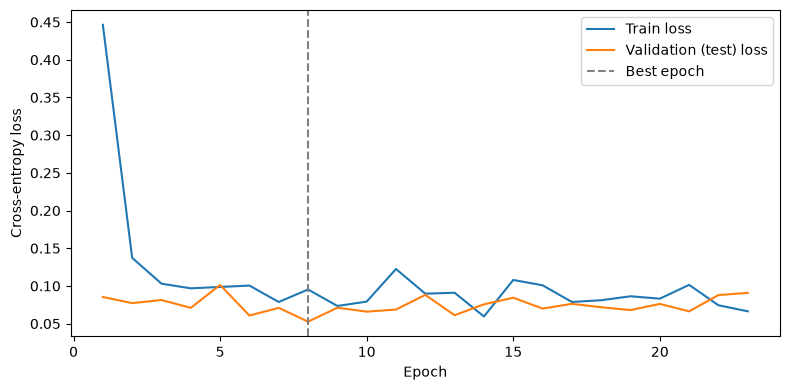

In [25]:
plt.figure(figsize=(8, 4))
epoch_range = range(1, len(train_losses) + 1)
plt.plot(epoch_range, train_losses, label="Train loss")
plt.plot(epoch_range, val_losses, label="Validation (test) loss")
plt.axvline(np.argmin(val_losses) + 1, color="gray", linestyle="--", label="Best epoch")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.tight_layout()
plt.show()


## **6. 모델 평가**

**Q1. 학습된 모델로 test 데이터에 대한 예측값을 구하세요.**

- 다중 분류에서 예측 클래스는 logit이 가장 큰 인덱스입니다.

Test accuracy (검증 겸용): 0.9848
                    precision    recall  f1-score   support

Cabernet Sauvignon       0.98      1.00      0.99       116
            Merlot       0.99      0.97      0.98       118
        Pinot Noir       0.98      0.99      0.98        96

          accuracy                           0.98       330
         macro avg       0.98      0.99      0.98       330
      weighted avg       0.98      0.98      0.98       330



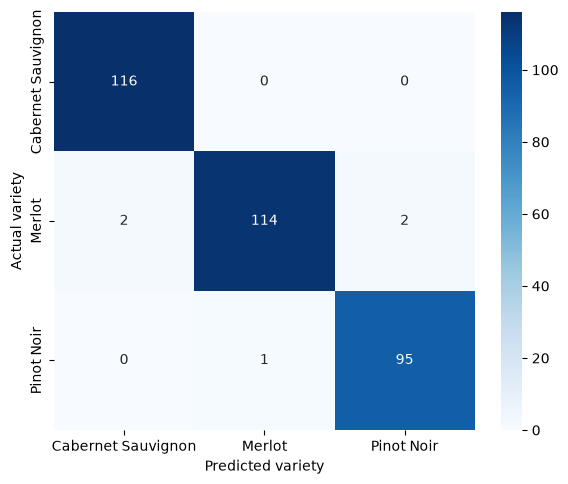

In [26]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    y_pred = test_logits.argmax(dim=1).cpu().numpy()

print(f"Test accuracy (검증 겸용): {accuracy_score(y_test_enc, y_pred):.4f}")
print(classification_report(
    y_test_enc, y_pred, labels=np.arange(n_classes),
    target_names=le_var.classes_, zero_division=0
))
plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix(y_test_enc, y_pred, labels=np.arange(n_classes)),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=le_var.classes_, yticklabels=le_var.classes_,
)
plt.xlabel("Predicted variety")
plt.ylabel("Actual variety")
plt.tight_layout()
plt.show()


## **7. 채점하기**

**미공개 데이터 URL:**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety_submission.csv

In [27]:
submission = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety_submission.csv")
submission.head()

,id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,oak_aged
0,1,13.801873,0.483173,2.647304,17.792411,106.619039,2.963929,3.126183,0.256605,1.277661,6.954893,1.021307,2.572290,1014.322862,Yes
1,2,13.297159,1.035745,2.203058,21.406817,118.154574,2.454447,2.060823,0.158903,2.252221,6.000669,0.885157,2.036313,1440.503122,No
2,3,14.529306,2.108780,2.302636,21.410780,121.280618,2.856354,2.815771,0.234276,1.527275,6.753056,1.158052,2.855995,1465.288950,Yes
3,4,11.720604,2.227718,2.078144,20.195159,78.944103,1.633732,1.573017,0.566970,1.984541,1.176633,1.314319,2.662910,571.455683,No
4,5,12.731468,0.964084,2.078431,25.308077,66.999211,2.033066,1.629994,0.373080,0.913899,2.549730,1.128514,2.560120,709.025018,Yes


In [28]:
# 동일한 전처리 적용
sub_X = submission.drop(["id"], axis=1).copy()

# 결측치
for col in cols_to_impute:
    sub_X[col] = sub_X[col].fillna(X_train[col].median())
sub_X["oak_aged"] = sub_X["oak_aged"].fillna(mode_val)

# 이상치
for c in numeric_cols:
    sub_X[c] = sub_X[c].clip(d[c][0], d[c][1])

# 인코딩
sub_X["oak_aged"] = le_oak.transform(sub_X["oak_aged"])

# 스케일링 & Tensor 변환
sub_scaled = scaler.transform(sub_X)
sub_t      = torch.tensor(sub_scaled, dtype=torch.float32)

In [32]:
# 학습 때와 같은 클래스 매핑으로 품종 이름을 복원합니다.
model.eval()
with torch.no_grad():
    sub_pred = model(sub_t).argmax(dim=1).cpu().numpy()

submission_result = pd.DataFrame({
    "id": submission["id"].to_numpy(),
    "variety": le_var.inverse_transform(sub_pred),
})
submission_result.to_csv("wine_variety_predictions.csv", index=False, encoding="utf-8-sig")
print("저장 완료: wine_variety_predictions.csv")
print("미공개 데이터에는 정답이 없어 정확도는 계산하지 않습니다.")
submission_result.head()


저장 완료: wine_variety_predictions.csv
미공개 데이터에는 정답이 없어 정확도는 계산하지 않습니다.


,id,variety
0,1,Cabernet Sauvignon
1,2,Cabernet Sauvignon
2,3,Cabernet Sauvignon
3,4,Merlot
4,5,Merlot
